Use a Random Forest Classifier and compare its results with Logistic Regression by tuning hyperparameters with RandomizedSearchCV, analyzing feature importance rankings, and performing SHAP value interpretation for explainability.

In [3]:
import pandas as pd
import numpy as np
import os
import joblib

In [4]:
save_folder = "task31_saved_files"

print("Saved files:")
for file in os.listdir(save_folder):
    print(file)


Saved files:
feature_config.pkl
logistic_regression_l1.pkl
logistic_regression_l2.pkl
preprocessor.pkl
random_forest_best.pkl
random_forest_best_params.pkl
x_test.pkl
x_train.pkl
y_test.pkl
y_train.pkl


In [5]:
save_folder = "task31_saved_files"

model_l1 = joblib.load(os.path.join(save_folder, "logistic_regression_l1.pkl"))
model_l2 = joblib.load(os.path.join(save_folder, "logistic_regression_l2.pkl"))
preprocessor = joblib.load(os.path.join(save_folder, "preprocessor.pkl"))
feature_config = joblib.load(os.path.join(save_folder, "feature_config.pkl"))
x_test = joblib.load(os.path.join(save_folder, "x_test.pkl"))
y_test = joblib.load(os.path.join(save_folder, "y_test.pkl"))
x_train = joblib.load(os.path.join(save_folder, "x_train.pkl"))
y_train = joblib.load(os.path.join(save_folder, "y_train.pkl"))
print("All saved files loaded successfully!")

All saved files loaded successfully!


In [6]:
print("X_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

print("\nx_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nSelected features:")
print(feature_config)

X_train shape: (18786, 15)
y_train shape: (18786,)

x_test shape: (4697, 15)
y_test shape: (4697,)

Training target distribution:
recommend_flag
1    15448
0     3338
Name: count, dtype: int64

Test target distribution:
recommend_flag
1    3863
0     834
Name: count, dtype: int64

Selected features:
{'numeric_features': ['customer_age', 'rating', 'vader_negative', 'vader_neutral', 'vader_positive', 'vader_compound', 'vader_sentiment_score'], 'categorical_features': ['category', 'subcategory1', 'subcategory2', 'location', 'channel', 'age_group', 'vader_sentiment_label'], 'text_feature': 'model_text', 'target_column': 'recommend_flag'}


Training data preprocess

In [7]:
from imblearn.over_sampling import SMOTE

In [8]:
save_folder = "task31_saved_files"

x_train_processed = preprocessor.transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("Processed training shape:", x_train_processed.shape)
print("Processed testing shape:", x_test_processed.shape)

# Balance only the training data using SMOTE
smote = SMOTE(random_state=42)

x_train_resampled, y_train_resampled = smote.fit_resample(x_train_processed, y_train)

print("\nBefore SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

print("\nResampled training shape:", x_train_resampled.shape)

Processed training shape: (18786, 3049)
Processed testing shape: (4697, 3049)

Before SMOTE:
recommend_flag
1    15448
0     3338
Name: count, dtype: int64

After SMOTE:
recommend_flag
0    15448
1    15448
Name: count, dtype: int64

Resampled training shape: (30896, 3049)


RandomizedSearchCV

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

In [10]:
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# Hyperparameter search space
param_distributions = {
    "n_estimators": randint(100, 401),
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 5),
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced"]
}

# 3-fold cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Randomized hyperparameter search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=10,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True
)

# Train and tune the model
random_search.fit(x_train_resampled, y_train_resampled)

best_rf = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(random_search.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 234}

Best Cross-Validation F1 Score:
0.9678


Saving best model

In [11]:
import os
import joblib

In [12]:
save_folder = 'task31_saved_files'
os.makedirs(save_folder, exist_ok=True)

joblib.dump(best_rf, os.path.join(save_folder, 'random_forest_best.pkl'))
joblib.dump(random_search.best_params_, os.path.join(save_folder, 'random_forest_best_params.pkl'))

print("Best Random Forest model saved successfully!")

Best Random Forest model saved successfully!


Evaluate all three models

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, cohen_kappa_score, matthews_corrcoef

In [14]:
best_rf = joblib.load(os.path.join('task31_saved_files', 'random_forest_best.pkl'))
models = {
    "Logistic Regression L1": model_l1,
    "Logistic Regression L2": model_l2,
    "Random Forest Tuned": best_rf
}

results = []
for name, model in models.items():
    # Random Forest and Logistic Regression use processed features
    y_pred = model.predict(x_test_processed)
    y_prob = model.predict_proba(x_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob),
        "Cohen Kappa": cohen_kappa_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

comparison_df = pd.DataFrame(results).sort_values(by='F1 Score', ascending=True).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision,Cohen Kappa,MCC
0,Random Forest Tuned,0.9378,0.9641,0.9601,0.9621,0.9720,0.9932,0.7887,0.7888
1,Logistic Regression L2,0.9402,0.9862,0.9405,0.9628,0.9793,0.9940,0.8111,0.8170
2,Logistic Regression L1,0.9402,0.9843,0.9423,0.9628,0.9784,0.9936,0.8099,0.8150


Feature importance

In [15]:
feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("Top 20 Random Forest Features:")
display(rf_importance.head(20).round(6))

Top 20 Random Forest Features:


,Feature,Importance
0,num__rating,0.158044
1,num__vader_sentiment_score,0.033292
2,num__vader_compound,0.031220
3,num__vader_negative,0.023331
4,num__vader_positive,0.021684
5,text__was,0.021544
6,text__not,0.014756
7,text__but,0.011138
8,text__back,0.010995
9,cat__vader_sentiment_label_Negative,0.010972


In [16]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import shap
import scipy.sparse as sp


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [28]:
# Select 100 test samples
x_shap = x_test_processed[:100]

# Convert sparse matrix or array to a numeric NumPy array
if sp.issparse(x_shap):
    x_shap = x_shap.toarray()
else:
    x_shap = np.asarray(x_shap)

x_shap = x_shap.astype(np.float32)

print("X_shap shape:", x_shap.shape)
print("X_shap dtype:", x_shap.dtype)
print("Contains NaN:", np.isnan(x_shap).any())

feature_names = preprocessor.get_feature_names_out()

X_shap shape: (100, 3049)
X_shap dtype: float32
Contains NaN: False


In [19]:
import numpy as np
import scipy.sparse as sp

# Ensure numeric dense input
x_shap = x_test_processed[:100]

if sp.issparse(x_shap):
    x_shap = x_shap.toarray()

x_shap = np.asarray(x_shap, dtype=np.float64)

print("Input shape:", x_shap.shape)
print("Model expected features:", best_rf.n_features_in_)
print("Input dtype:", x_shap.dtype)
print("Contains NaN:", np.isnan(x_shap).any())
print("Contains Inf:", np.isinf(x_shap).any())

print("\nModel prediction sample:")
print(best_rf.predict_proba(x_shap[:5])[:, 1])

Input shape: (100, 3049)
Model expected features: 3049
Input dtype: float64
Contains NaN: False
Contains Inf: False

Model prediction sample:
[0.72435897 0.9227208  0.93547009 0.92820513 0.90754986]


Create SHAP explainer

In [20]:
x_background = x_train_processed[:50]

if hasattr(x_background, 'toarray'):
    x_background = x_background.toarray()

x_background = np.asarray(x_background, dtype=np.float64)

# Interventional SHAP explainer
explainer = shap.TreeExplainer(best_rf, data=x_background, feature_perturbation='interventional', model_output='probability')

# Calculate SHAP values
shap_values = explainer.shap_values(x_shap, check_additivity=False)
print("SHAP calculation completed!")



 97%|=================== | 194/200 [00:28<00:00]       

SHAP calculation completed!


Extract positive-class SHAP values

In [21]:
if isinstance(shap_values, list):
    positive_shap = np.asarray(shap_values[1])

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    positive_shap = np.asarray(shap_values[:, :, 1])

else:
    positive_shap = np.asarray(shap_values)


print("SHAP shape:", positive_shap.shape)
print("All values finite:", np.isfinite(positive_shap).all())

SHAP shape: (100, 3049)
All values finite: True


SHAP summary plot

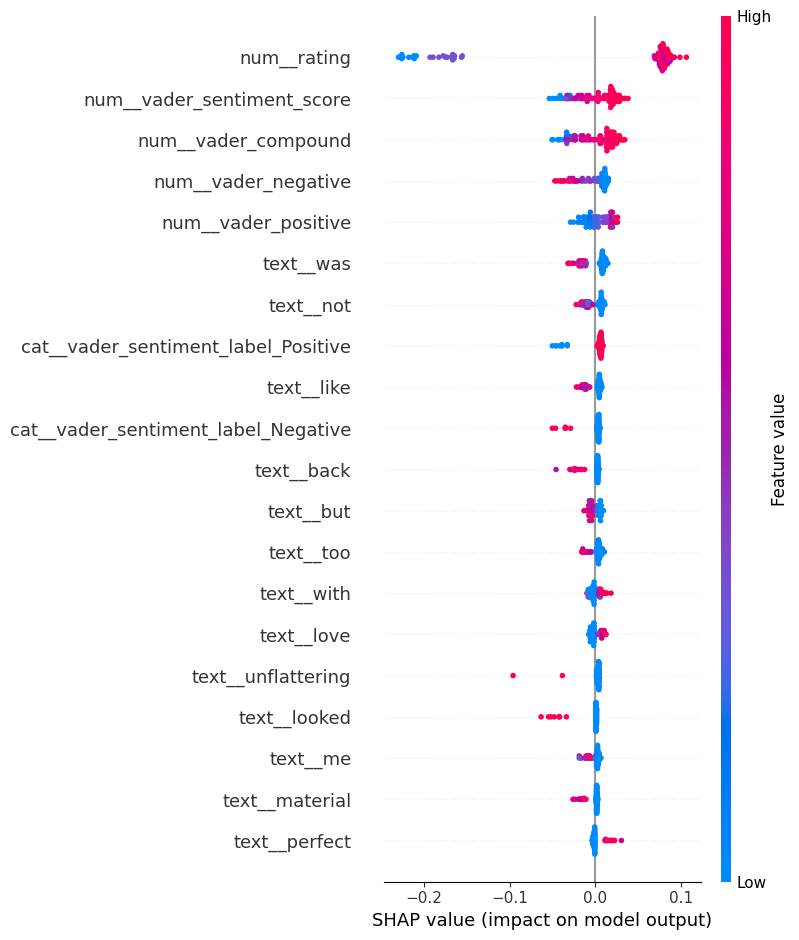

In [25]:
feature_names = preprocessor.get_feature_names_out()

shap.summary_plot(positive_shap, x_shap, feature_names, max_display=20)

SHAP feature importance

In [27]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(positive_shap).mean(axis=0)
}).sort_values(by="Mean Absolute SHAP", ascending=False).reset_index(drop=True)

print("Top 20 SHAP Features:")
display(shap_importance.head(20).round(6))

Top 20 SHAP Features:


,Feature,Mean Absolute SHAP
0,num__rating,0.109610
1,num__vader_sentiment_score,0.020847
2,num__vader_compound,0.020133
3,num__vader_negative,0.013959
4,num__vader_positive,0.012090
5,text__was,0.011884
6,text__not,0.009043
7,cat__vader_sentiment_label_Positive,0.008954
8,text__like,0.007190
9,cat__vader_sentiment_label_Negative,0.005474


SHAP tells us how much each feature contributes to a model's prediction.

### Conclusion

In this task, a Random Forest Classifier was implemented and its hyperparameters were optimized using RandomizedSearchCV with 3-fold Stratified Cross-Validation. The tuned Random Forest model was evaluated and compared with Logistic Regression models using L1 and L2 regularization on the same test dataset.

The comparison showed that Logistic Regression achieved slightly better accuracy (94.02%), F1-score (96.28%), and ROC-AUC (97.93%) than the tuned Random Forest, while Random Forest achieved a higher recall of 96.01%. These results indicate that both models performed well, with Logistic Regression showing slightly better overall performance across several evaluation metrics.

Random Forest feature importance analysis identified `rating` as the most influential feature, followed by sentiment-related numerical features and review-text terms. SHAP analysis provided further explainability by showing how individual features influenced the model's predictions. The SHAP summary plot indicated that higher ratings and positive sentiment generally contributed towards the recommended class, whereas lower ratings and negative sentiment generally contributed towards the non-recommended class.

Overall, this task demonstrated the importance of hyperparameter optimization, model comparison, feature importance analysis, and explainable AI techniques in building and understanding machine learning models. It also highlighted that model selection should consider multiple evaluation metrics and the availability of input features in real-world prediction scenarios.